# Within-Subject Recognition-Memory EEG Decoding (Participant 3076)

## Purpose

This notebook loads the cleaned epochs created in [Notebook 01](01_preprocess_and_epoch_thapar_3076.ipynb) and evaluates whether EEG can distinguish `correct_old` from `correct_new` trials for participant 3076. It does not alter the raw recording or the preprocessing performed in Notebook 01.

The analysis compares three pre-specified approaches:

- A chance-level dummy classifier
- Time-binned ERP features with regularized logistic regression
- Filter-bank common spatial patterns (FBCSP) with LDA
- An exploratory EEGNet convolutional neural network

## Scope and interpretation

This is a **within-subject, trial-level** decoding analysis. It does not classify a patient or establish a clinical diagnostic model. `correct_old` combines hits for once- and twice-studied items, while `correct_new` represents correct rejections. The label therefore reflects experimental condition and response outcome; successful decoding should not be interpreted as a pure measure of memory strength alone.

## Evaluation protocol

The saved epochs do not contain run metadata. Instead, this notebook detects the three naturally separated recording blocks from gaps between chronological event samples:

1. **Block 1:** model fitting
2. **Block 2:** validation and model-development decisions
3. **Block 3:** final held-out test set

Scalers, CSP filters, feature selection, and neural-network parameters are always fit on earlier data only. The final block must remain untouched while changing features, hyperparameters, or model architecture.

## 1. Imports and reproducibility

In [1]:
from pathlib import Path
import copy
import random

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import display
from mne.decoding import CSP
from sklearn.dummy import DummyClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

from braindecode.models import EEGNet

SEED = 97
np.random.seed(SEED)
random.seed(SEED)
torch.manual_seed(SEED)

mne.set_log_level("WARNING")
plt.style.use("seaborn-v0_8-whitegrid")

print(f"MNE: {mne.__version__}")
print(f"PyTorch: {torch.__version__}")

MNE: 1.13.2
PyTorch: 2.11.0


/opt/anaconda3/envs/thapar-eeg/lib/python3.12/site-packages/braindecode/models/eegpt.py:497: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  montage = mne.channels.make_standard_montage("standard_1020")
/opt/anaconda3/envs/thapar-eeg/lib/python3.12/site-packages/braindecode/models/eegpt.py:1452: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  montage = make_standard_montage("standard_1020")


## 2. Load the cleaned epochs

Run this notebook from either the repository root or its notebooks directory. The path finder below keeps the notebook portable after cloning the repository.

In [2]:
def find_project_folder(start_folder):
    """Locate the project folder containing data/processed."""
    for folder in [start_folder, *start_folder.parents]:
        if (folder / "data" / "processed").exists():
            return folder
    raise FileNotFoundError(
        "Could not find data/processed. Open the notebook from the project "
        "root or its notebooks directory."
    )


project_folder = find_project_folder(Path.cwd().resolve())
participant_id = "3076"
epochs_file = project_folder / "data" / "processed" / f"{participant_id}_clean-epo.fif"
figures_folder = project_folder / "results" / "figures" / "decoding" / participant_id
figures_folder.mkdir(parents=True, exist_ok=True)

epochs = mne.read_epochs(epochs_file, preload=True, verbose="ERROR")

scalp_picks = mne.pick_types(
    epochs.info,
    eeg=True,
    eog=False,
)
scalp_channel_names = np.array(epochs.ch_names)[scalp_picks]

X_eeg = epochs.get_data(picks=scalp_picks)
y = (epochs.events[:, 2] == epochs.event_id["correct_new"]).astype(int)
class_names = ["correct_old", "correct_new"]

assert X_eeg.shape[0] == len(y)
assert set(np.unique(y)) == {0, 1}

print(f"Loaded: {epochs_file.name}")
print(f"EEG data shape: {X_eeg.shape} (epochs, channels, samples)")
print(f"Sampling rate: {epochs.info['sfreq']} Hz")
print(f"Epoch window: {epochs.times[0]:.1f} to {epochs.times[-1]:.1f} seconds")
print(f"Correct-old: {(y == 0).sum()} | Correct-new: {(y == 1).sum()}")

Loaded: 3076_clean-epo.fif
EEG data shape: (196, 32, 426) (epochs, channels, samples)
Sampling rate: 250.0 Hz
Epoch window: -0.2 to 1.5 seconds
Correct-old: 79 | Correct-new: 117


### Create a chronological, blocked split

A random epoch split would mix nearby trials between development and test sets, which can inflate apparent performance. Here, a gap greater than 60 seconds starts a new recording block.

,epochs,correct_old,correct_new,first_event_s,last_event_s
Block 1: train,71,33,38,247.9,942.5
Block 2: validation,63,24,39,1221.5,1933.7
Block 3: final test,62,22,40,2363.6,3078.7


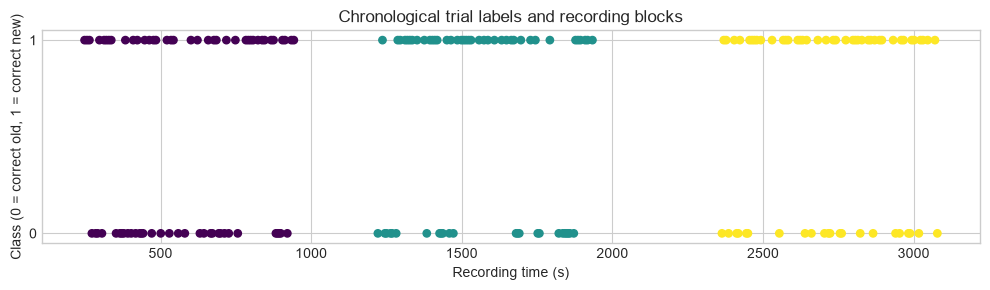

In [3]:
BLOCK_GAP_SECONDS = 60
event_seconds = epochs.events[:, 0] / epochs.info["sfreq"]
event_gaps = np.diff(event_seconds)
block_id = np.r_[0, np.cumsum(event_gaps > BLOCK_GAP_SECONDS)]
n_blocks = int(block_id.max() + 1)

if n_blocks != 3:
    raise RuntimeError(
        f"Expected 3 natural recording blocks; found {n_blocks}. "
        "Inspect the event gaps before changing the split."
    )

block_summary = (
    pd.DataFrame(
        {
            "block": block_id,
            "label": np.where(y == 1, "correct_new", "correct_old"),
            "event_time_s": event_seconds,
        }
    )
    .groupby("block")
    .agg(
        epochs=("label", "size"),
        correct_old=("label", lambda values: (values == "correct_old").sum()),
        correct_new=("label", lambda values: (values == "correct_new").sum()),
        first_event_s=("event_time_s", "min"),
        last_event_s=("event_time_s", "max"),
    )
)
block_summary.index = ["Block 1: train", "Block 2: validation", "Block 3: final test"]
display(block_summary.round(1))

train_index = np.flatnonzero(block_id == 0)
validation_index = np.flatnonzero(block_id == 1)
test_index = np.flatnonzero(block_id == 2)
train_validation_index = np.r_[train_index, validation_index]

figure, axis = plt.subplots(figsize=(10, 3))
axis.scatter(event_seconds, y, c=block_id, cmap="viridis", s=28)
axis.set(
    title="Chronological trial labels and recording blocks",
    xlabel="Recording time (s)",
    ylabel="Class (0 = correct old, 1 = correct new)",
    yticks=[0, 1],
)
figure.tight_layout()
figure.savefig(figures_folder / "chronological_blocks.png", dpi=300, bbox_inches="tight")
plt.show()

## 3. Interpretable baseline: time-binned ERP features + logistic regression

Each scalp channel is averaged within ten 100-ms post-stimulus windows from 0.2 to 1.2 seconds. This yields 320 features per trial: 32 scalp channels × 10 time bins. The scaler and classifier are fit only on the earlier blocks.

In [4]:
BIN_START_SECONDS = 0.2
BIN_END_SECONDS = 1.2
BIN_WIDTH_SECONDS = 0.1
bin_edges = np.arange(
    BIN_START_SECONDS,
    BIN_END_SECONDS + 1e-9,
    BIN_WIDTH_SECONDS,
)


def make_time_bin_features(eeg_data, times, edges):
    """Average each channel within each pre-specified post-stimulus time bin."""
    bin_averages = []
    for left_edge, right_edge in zip(edges[:-1], edges[1:]):
        sample_mask = (times >= left_edge) & (times < right_edge)
        if not sample_mask.any():
            raise ValueError(f"No samples found in {left_edge}-{right_edge} s bin.")
        bin_averages.append(eeg_data[:, :, sample_mask].mean(axis=2))

    features = np.stack(bin_averages, axis=2)
    return (features * 1e6).reshape(features.shape[0], -1)


X_erp = make_time_bin_features(X_eeg, epochs.times, bin_edges)
print(f"ERP feature matrix: {X_erp.shape} (epochs, features)")

ERP feature matrix: (196, 320) (epochs, features)


In [5]:
def make_logistic_regression():
    return Pipeline(
        steps=[
            ("scaler", StandardScaler()),
            (
                "classifier",
                LogisticRegression(
                    C=1.0,
                    class_weight="balanced",
                    max_iter=5_000,
                    random_state=SEED,
                    solver="liblinear",
                ),
            ),
        ]
    )


def score_predictions(y_true, y_pred, model_name, split_name):
    return {
        "Model": model_name,
        "Split": split_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced accuracy": balanced_accuracy_score(y_true, y_pred),
    }


validation_results = []

dummy_model = DummyClassifier(strategy="prior")
dummy_model.fit(X_erp[train_index], y[train_index])
dummy_validation_prediction = dummy_model.predict(X_erp[validation_index])
validation_results.append(
    score_predictions(
        y[validation_index],
        dummy_validation_prediction,
        "Dummy majority-class baseline",
        "Validation (Block 2)",
    )
)

logistic_model = make_logistic_regression()
logistic_model.fit(X_erp[train_index], y[train_index])
logistic_validation_prediction = logistic_model.predict(X_erp[validation_index])
validation_results.append(
    score_predictions(
        y[validation_index],
        logistic_validation_prediction,
        "Time-binned ERP + logistic regression",
        "Validation (Block 2)",
    )
)

display(pd.DataFrame(validation_results).set_index("Model").round(3))

,Split,Accuracy,Balanced accuracy
Model,,,
Dummy majority-class baseline,Validation (Block 2),0.619,0.500
Time-binned ERP + logistic regression,Validation (Block 2),0.619,0.604


### Final test for the ERP baseline

The logistic-regression specification above is fixed before looking at the final block. It is now refit using Blocks 1 and 2, then evaluated once on Block 3.

                                                      Split  Accuracy  \
Model                                                                   
Time-binned ERP + logistic regression  Final test (Block 3)     0.661   

                                       Balanced accuracy  
Model                                                     
Time-binned ERP + logistic regression              0.635  


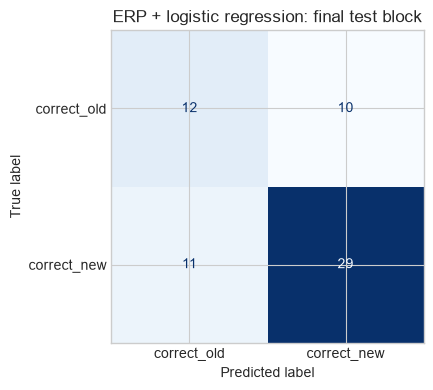

In [6]:
final_results = []

logistic_final_model = make_logistic_regression()
logistic_final_model.fit(X_erp[train_validation_index], y[train_validation_index])
logistic_test_prediction = logistic_final_model.predict(X_erp[test_index])
final_results.append(
    score_predictions(
        y[test_index],
        logistic_test_prediction,
        "Time-binned ERP + logistic regression",
        "Final test (Block 3)",
    )
)

print(pd.DataFrame(final_results).set_index("Model").round(3))

figure, axis = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y[test_index],
    logistic_test_prediction,
    display_labels=class_names,
    cmap="Blues",
    colorbar=False,
    ax=axis,
)
axis.set_title("ERP + logistic regression: final test block")
figure.tight_layout()
figure.savefig(figures_folder / "erp_logistic_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

In [7]:
def stratified_bootstrap_balanced_accuracy(
    y_true,
    y_pred,
    n_bootstrap=2_000,
    seed=SEED,
):
    """Return a conditional 95% bootstrap CI for held-out balanced accuracy."""
    generator = np.random.default_rng(seed)
    class_indices = [np.flatnonzero(y_true == label) for label in np.unique(y_true)]
    scores = []

    for _ in range(n_bootstrap):
        resampled_index = np.concatenate(
            [
                generator.choice(indices, size=len(indices), replace=True)
                for indices in class_indices
            ]
        )
        scores.append(
            balanced_accuracy_score(
                y_true[resampled_index],
                y_pred[resampled_index],
            )
        )

    return np.quantile(scores, [0.025, 0.975])


erp_ci = stratified_bootstrap_balanced_accuracy(
    y[test_index],
    logistic_test_prediction,
)
erp_balanced_accuracy = balanced_accuracy_score(
    y[test_index],
    logistic_test_prediction,
)
print(
    "ERP + logistic regression final-test balanced accuracy: "
    f"{erp_balanced_accuracy:.3f} "
    f"(95% bootstrap CI: {erp_ci[0]:.3f} to {erp_ci[1]:.3f})"
)

ERP + logistic regression final-test balanced accuracy: 0.635 (95% bootstrap CI: 0.509 to 0.761)


## 4. FBCSP + LDA comparator

FBCSP filters the data into multiple frequency bands, learns class-sensitive spatial filters separately in each band, selects features using training data only, and classifies the selected features with regularized LDA. Because this is a pre-specified comparator, its validation and final-test results are reported alongside the ERP baseline.

In [8]:
FREQUENCY_BANDS = [
    (4, 8),
    (8, 12),
    (12, 16),
    (16, 20),
    (20, 24),
    (24, 28),
    (28, 32),
    (32, 36),
]
N_CSP_COMPONENTS = 4
N_SELECTED_FEATURES = 8


def bandpass_epochs(eeg_data, sampling_rate, low_frequency, high_frequency):
    """Apply an IIR band-pass filter independently to each epoch.

    IIR filtering avoids a long-FIR-filter warning for these short epochs.
    """
    return mne.filter.filter_data(
        eeg_data.copy(),
        sfreq=sampling_rate,
        l_freq=low_frequency,
        h_freq=high_frequency,
        method="iir",
        iir_params={"order": 4, "ftype": "butter"},
        verbose="ERROR",
    )


def fbcsp_fit_predict(X_fit, y_fit, X_predict, sampling_rate):
    """Fit FBCSP and LDA on X_fit, then predict X_predict without leakage."""
    fit_features_by_band = []
    predict_features_by_band = []
    feature_names = []

    for low_frequency, high_frequency in FREQUENCY_BANDS:
        X_fit_band = bandpass_epochs(
            X_fit, sampling_rate, low_frequency, high_frequency
        )
        X_predict_band = bandpass_epochs(
            X_predict, sampling_rate, low_frequency, high_frequency
        )

        csp = CSP(
            n_components=N_CSP_COMPONENTS,
            reg="oas",
            log=True,
            norm_trace=False,
        )
        fit_features_by_band.append(csp.fit_transform(X_fit_band, y_fit))
        predict_features_by_band.append(csp.transform(X_predict_band))
        feature_names.extend(
            [
                f"{low_frequency}-{high_frequency} Hz, CSP {component + 1}"
                for component in range(N_CSP_COMPONENTS)
            ]
        )

    X_fit_features = np.concatenate(fit_features_by_band, axis=1)
    X_predict_features = np.concatenate(predict_features_by_band, axis=1)

    selector = SelectKBest(
        score_func=f_classif,
        k=N_SELECTED_FEATURES,
    )
    X_fit_selected = selector.fit_transform(X_fit_features, y_fit)
    X_predict_selected = selector.transform(X_predict_features)

    classifier = LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto",
    )
    classifier.fit(X_fit_selected, y_fit)

    details = {
        "selected_feature_names": np.array(feature_names)[
            selector.get_support(indices=True)
        ],
        "selected_feature_scores": selector.scores_[
            selector.get_support(indices=True)
        ],
    }
    return classifier.predict(X_predict_selected), details


fbcsp_validation_prediction, _ = fbcsp_fit_predict(
    X_eeg[train_index],
    y[train_index],
    X_eeg[validation_index],
    epochs.info["sfreq"],
)
validation_results.append(
    score_predictions(
        y[validation_index],
        fbcsp_validation_prediction,
        "FBCSP + LDA",
        "Validation (Block 2)",
    )
)

display(pd.DataFrame(validation_results).set_index("Model").round(3))

,Split,Accuracy,Balanced accuracy
Model,,,
Dummy majority-class baseline,Validation (Block 2),0.619,0.500
Time-binned ERP + logistic regression,Validation (Block 2),0.619,0.604
FBCSP + LDA,Validation (Block 2),0.730,0.694


,Selected FBCSP feature,Training ANOVA F score
3,"24-28 Hz, CSP 2",55.914
6,"28-32 Hz, CSP 4",54.876
5,"28-32 Hz, CSP 1",51.688
2,"16-20 Hz, CSP 1",45.535
0,"12-16 Hz, CSP 1",44.448
1,"12-16 Hz, CSP 4",41.908
7,"32-36 Hz, CSP 1",41.849
4,"24-28 Hz, CSP 4",38.993


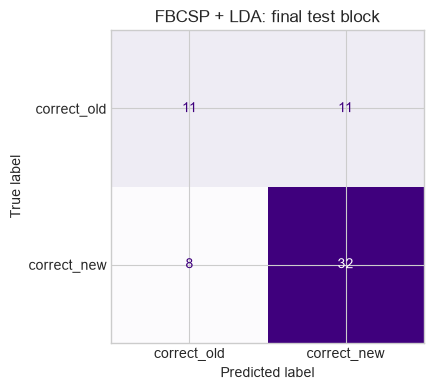

In [9]:
fbcsp_test_prediction, fbcsp_details = fbcsp_fit_predict(
    X_eeg[train_validation_index],
    y[train_validation_index],
    X_eeg[test_index],
    epochs.info["sfreq"],
)
final_results.append(
    score_predictions(
        y[test_index],
        fbcsp_test_prediction,
        "FBCSP + LDA",
        "Final test (Block 3)",
    )
)

selected_feature_table = pd.DataFrame(
    {
        "Selected FBCSP feature": fbcsp_details["selected_feature_names"],
        "Training ANOVA F score": fbcsp_details["selected_feature_scores"],
    }
).sort_values("Training ANOVA F score", ascending=False)
display(selected_feature_table.round(3))

figure, axis = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y[test_index],
    fbcsp_test_prediction,
    display_labels=class_names,
    cmap="Purples",
    colorbar=False,
    ax=axis,
)
axis.set_title("FBCSP + LDA: final test block")
figure.tight_layout()
figure.savefig(figures_folder / "fbcsp_lda_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

## 5. Exploratory EEGNet comparator

EEGNet learns temporal and spatial filters directly from the cleaned EEG time series. With only 196 total trials, this model is exploratory and may have high variance. Block 2 is used only to select the number of training epochs through early stopping. The final CNN is then retrained on Blocks 1 and 2 for that pre-selected number of epochs before it sees Block 3.

In [10]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MAX_EPOCHS = 75
PATIENCE = 12
BATCH_SIZE = 16


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def standardize_channels(X_fit, X_apply):
    """Use channel statistics from fitting data only."""
    channel_mean = X_fit.mean(axis=(0, 2), keepdims=True)
    channel_std = X_fit.std(axis=(0, 2), keepdims=True)
    channel_std = np.where(channel_std == 0, 1.0, channel_std)
    return ((X_apply - channel_mean) / channel_std).astype(np.float32)


def make_eegnet(n_channels, n_times, sampling_rate):
    return EEGNet(
        n_chans=n_channels,
        n_outputs=2,
        n_times=n_times,
        sfreq=sampling_rate,
        F1=8,
        D=2,
        F2=16,
        kernel_length=64,
        drop_prob=0.5,
    ).to(DEVICE)


def prediction_from_model(model, X):
    model.eval()
    with torch.no_grad():
        logits = model(torch.from_numpy(X).to(DEVICE))
    return logits.argmax(dim=1).cpu().numpy()


def train_eegnet_with_validation(X_train, y_train, X_validation, y_validation):
    """Fit EEGNet and retain the state with the lowest validation loss."""
    set_seed(SEED)
    model = make_eegnet(
        n_channels=X_train.shape[1],
        n_times=X_train.shape[2],
        sampling_rate=epochs.info["sfreq"],
    )
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)
    loss_function = nn.CrossEntropyLoss()
    train_loader = DataLoader(
        TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train)),
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=torch.Generator().manual_seed(SEED),
    )
    validation_X = torch.from_numpy(X_validation).to(DEVICE)
    validation_y = torch.from_numpy(y_validation).to(DEVICE)

    best_validation_loss = np.inf
    best_state = None
    best_epoch = 0
    history = []

    for epoch_number in range(1, MAX_EPOCHS + 1):
        model.train()
        training_loss_total = 0.0
        training_count = 0

        for batch_X, batch_y in train_loader:
            batch_X = batch_X.to(DEVICE)
            batch_y = batch_y.to(DEVICE)
            optimizer.zero_grad()
            logits = model(batch_X)
            loss = loss_function(logits, batch_y)
            loss.backward()
            optimizer.step()
            training_loss_total += loss.item() * len(batch_y)
            training_count += len(batch_y)

        model.eval()
        with torch.no_grad():
            validation_logits = model(validation_X)
            validation_loss = loss_function(validation_logits, validation_y).item()
            validation_accuracy = (
                validation_logits.argmax(dim=1) == validation_y
            ).float().mean().item()

        training_loss = training_loss_total / training_count
        history.append(
            {
                "epoch": epoch_number,
                "training_loss": training_loss,
                "validation_loss": validation_loss,
                "validation_accuracy": validation_accuracy,
            }
        )

        if validation_loss < best_validation_loss:
            best_validation_loss = validation_loss
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch_number
        elif epoch_number - best_epoch >= PATIENCE:
            break

    model.load_state_dict(best_state)
    return model, pd.DataFrame(history), best_epoch


def train_eegnet_for_fixed_epochs(X_train, y_train, n_epochs):
    """Retrain on all development data for a validation-selected epoch count."""
    set_seed(SEED)
    model = make_eegnet(
        n_channels=X_train.shape[1],
        n_times=X_train.shape[2],
        sampling_rate=epochs.info["sfreq"],
    )
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)
    loss_function = nn.CrossEntropyLoss()
    train_loader = DataLoader(
        TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train)),
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=torch.Generator().manual_seed(SEED),
    )

    for _ in range(n_epochs):
        model.train()
        for batch_X, batch_y in train_loader:
            batch_X = batch_X.to(DEVICE)
            batch_y = batch_y.to(DEVICE)
            optimizer.zero_grad()
            loss = loss_function(model(batch_X), batch_y)
            loss.backward()
            optimizer.step()

    return model


print(f"Using device: {DEVICE}")

Using device: cpu


Validation-selected epoch count: 35


,Split,Accuracy,Balanced accuracy
Model,,,
Dummy majority-class baseline,Validation (Block 2),0.619,0.500
Time-binned ERP + logistic regression,Validation (Block 2),0.619,0.604
FBCSP + LDA,Validation (Block 2),0.730,0.694
EEGNet,Validation (Block 2),0.603,0.607


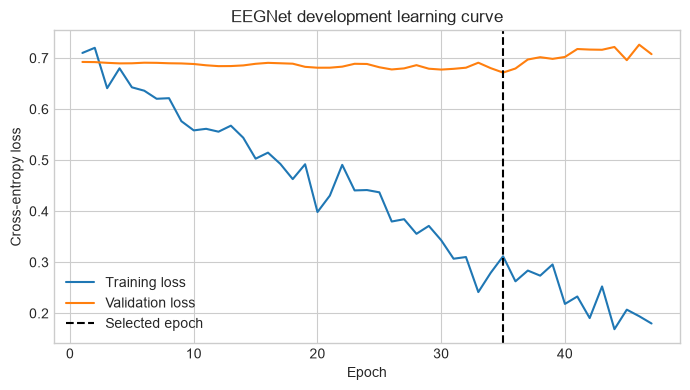

In [11]:
X_cnn_train = standardize_channels(X_eeg[train_index], X_eeg[train_index])
X_cnn_validation = standardize_channels(X_eeg[train_index], X_eeg[validation_index])

eegnet_validation_model, training_history, selected_epoch_count = train_eegnet_with_validation(
    X_cnn_train,
    y[train_index],
    X_cnn_validation,
    y[validation_index],
)
eegnet_validation_prediction = prediction_from_model(
    eegnet_validation_model,
    X_cnn_validation,
)
validation_results.append(
    score_predictions(
        y[validation_index],
        eegnet_validation_prediction,
        "EEGNet",
        "Validation (Block 2)",
    )
)

print(f"Validation-selected epoch count: {selected_epoch_count}")
display(pd.DataFrame(validation_results).set_index("Model").round(3))

figure, axis = plt.subplots(figsize=(7, 4))
axis.plot(training_history["epoch"], training_history["training_loss"], label="Training loss")
axis.plot(training_history["epoch"], training_history["validation_loss"], label="Validation loss")
axis.axvline(selected_epoch_count, color="black", linestyle="--", label="Selected epoch")
axis.set(
    title="EEGNet development learning curve",
    xlabel="Epoch",
    ylabel="Cross-entropy loss",
)
axis.legend()
figure.tight_layout()
figure.savefig(figures_folder / "eegnet_learning_curve.png", dpi=300, bbox_inches="tight")
plt.show()

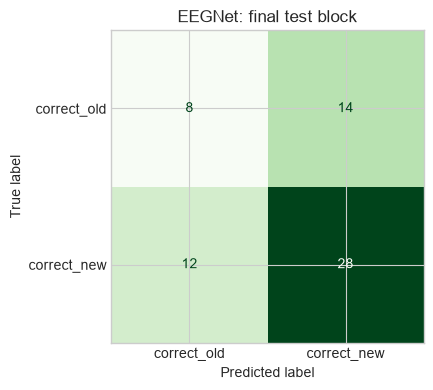

In [12]:
X_cnn_train_validation = standardize_channels(
    X_eeg[train_validation_index],
    X_eeg[train_validation_index],
)
X_cnn_test = standardize_channels(
    X_eeg[train_validation_index],
    X_eeg[test_index],
)

eegnet_final_model = train_eegnet_for_fixed_epochs(
    X_cnn_train_validation,
    y[train_validation_index],
    selected_epoch_count,
)
eegnet_test_prediction = prediction_from_model(eegnet_final_model, X_cnn_test)
final_results.append(
    score_predictions(
        y[test_index],
        eegnet_test_prediction,
        "EEGNet",
        "Final test (Block 3)",
    )
)

figure, axis = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y[test_index],
    eegnet_test_prediction,
    display_labels=class_names,
    cmap="Greens",
    colorbar=False,
    ax=axis,
)
axis.set_title("EEGNet: final test block")
figure.tight_layout()
figure.savefig(figures_folder / "eegnet_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. Final comparison and interpretation

The table below summarizes pre-specified models on the same untouched final block. Balanced accuracy is the primary metric because the classes are not equally frequent. Do not tune a model after viewing this table and continue to call Block 3 a held-out test set; that would require a new untouched evaluation set.

,Accuracy,Balanced accuracy
Model,,
FBCSP + LDA,0.694,0.650
Time-binned ERP + logistic regression,0.661,0.635
EEGNet,0.581,0.532


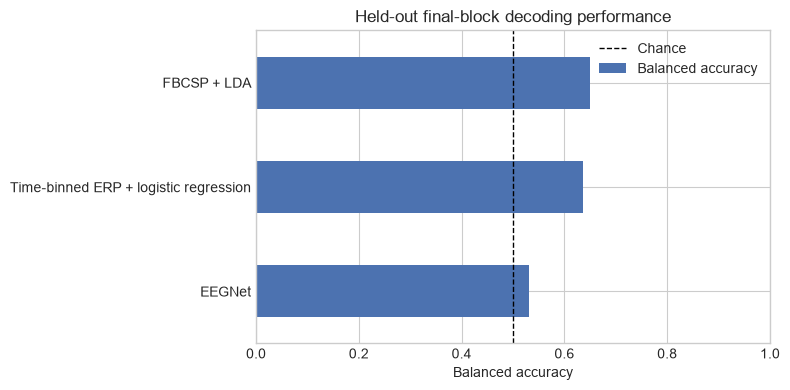

In [13]:
validation_table = pd.DataFrame(validation_results).set_index("Model")
final_table = pd.DataFrame(final_results).set_index("Model")

display(
    final_table[["Accuracy", "Balanced accuracy"]]
    .sort_values("Balanced accuracy", ascending=False)
    .round(3)
)

figure, axis = plt.subplots(figsize=(8, 4))
(
    final_table.sort_values("Balanced accuracy", ascending=True)["Balanced accuracy"]
    .plot.barh(ax=axis, color="#4C72B0", legend=False)
)
axis.axvline(0.5, color="black", linestyle="--", linewidth=1, label="Chance")
axis.set(
    title="Held-out final-block decoding performance",
    xlabel="Balanced accuracy",
    ylabel="",
    xlim=(0, 1),
)
axis.legend()
figure.tight_layout()
figure.savefig(figures_folder / "final_model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

## Limitations and next steps

- These results apply only to participant 3076 and should not be described as cross-subject or clinical generalization.
- The target combines old/new item status with response outcome. Stimulus properties, decision processes, and response preparation may contribute to decoding performance.
- The natural recording blocks help prevent nearby-trial leakage, but temporal drift and unequal class counts still make this a difficult, small-sample problem.
- Before modifying models based on final-test performance, preserve a new untouched test set or repeat the analysis using a nested validation design.
- The next project step is to run the same preprocessing and blocked decoding protocol for participants 3087 and 3103, then summarize the distribution of within-subject results.
- A later cross-subject model should use participant-level held-out evaluation; it is a different and much harder question than the one answered here.